In [68]:
import warnings

warnings.filterwarnings("ignore")

# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# File handling
import os

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Libraries imported successfully.")

Libraries imported successfully.


In [69]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("radheshyamkollipara/bank-customer-churn")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\Minn Bern\.cache\kagglehub\datasets\radheshyamkollipara\bank-customer-churn\versions\1


In [70]:
df_raw = pd.read_csv(
    os.path.join(path, "Customer-Churn-Records.csv")
)

print("Dataset loaded successfully.")
print(f"Rows    : {df_raw.shape[0]:,}")
print(f"Columns : {df_raw.shape[1]:,}")

Dataset loaded successfully.
Rows    : 10,000
Columns : 18


In [71]:
# Column information
print(f"{'#':<5} {'Column':<30} {'Dtype':<15}")

for i, (col, dtype) in enumerate(df_raw.dtypes.items(), 1):
    print(f"{i:<5} {col:<30} {str(dtype):<15}")

#     Column                         Dtype          
1     RowNumber                      int64          
2     CustomerId                     int64          
3     Surname                        str            
4     CreditScore                    int64          
5     Geography                      str            
6     Gender                         str            
7     Age                            int64          
8     Tenure                         int64          
9     Balance                        float64        
10    NumOfProducts                  int64          
11    HasCrCard                      int64          
12    IsActiveMember                 int64          
13    EstimatedSalary                float64        
14    Exited                         int64          
15    Complain                       int64          
16    Satisfaction Score             int64          
17    Card Type                      str            
18    Point Earned                   int64    

In [72]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   RowNumber           10000 non-null  int64  
 1   CustomerId          10000 non-null  int64  
 2   Surname             10000 non-null  str    
 3   CreditScore         10000 non-null  int64  
 4   Geography           10000 non-null  str    
 5   Gender              10000 non-null  str    
 6   Age                 10000 non-null  int64  
 7   Tenure              10000 non-null  int64  
 8   Balance             10000 non-null  float64
 9   NumOfProducts       10000 non-null  int64  
 10  HasCrCard           10000 non-null  int64  
 11  IsActiveMember      10000 non-null  int64  
 12  EstimatedSalary     10000 non-null  float64
 13  Exited              10000 non-null  int64  
 14  Complain            10000 non-null  int64  
 15  Satisfaction Score  10000 non-null  int64  
 16  Card Type       

In [73]:
df_raw.head(10)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,"101,348.88",1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,"83,807.86",1,0,1,"112,542.58",0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,"159,660.80",3,1,0,"113,931.57",1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,"93,826.63",0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,"125,510.82",1,1,1,"79,084.10",0,0,5,GOLD,425
5,6,15574012,Chu,645,Spain,Male,44,8,"113,755.78",2,1,0,"149,756.71",1,1,5,DIAMOND,484
6,7,15592531,Bartlett,822,France,Male,50,7,0.00,2,1,1,"10,062.80",0,0,2,SILVER,206
7,8,15656148,Obinna,376,Germany,Female,29,4,"115,046.74",4,1,0,"119,346.88",1,1,2,DIAMOND,282
8,9,15792365,He,501,France,Male,44,4,"142,051.07",2,0,1,"74,940.50",0,0,3,GOLD,251
9,10,15592389,H?,684,France,Male,27,2,"134,603.88",1,1,1,"71,725.73",0,0,3,GOLD,342


In [74]:
df_raw.sample(10, random_state=42)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
6252,6253,15687492,Anderson,596,Germany,Male,32,3,"96,709.07",2,0,0,"41,788.37",0,0,1,GOLD,709
4684,4685,15736963,Herring,623,France,Male,43,1,0.00,2,1,1,"146,379.30",0,0,2,SILVER,508
1731,1732,15721730,Amechi,601,Spain,Female,44,4,0.00,2,1,0,"58,561.31",0,0,1,GOLD,281
4742,4743,15762134,Liang,506,Germany,Male,59,8,"119,152.10",2,1,1,"170,679.74",0,0,2,SILVER,979
4521,4522,15648898,Chuang,560,Spain,Female,27,7,"124,995.98",1,1,1,"114,669.79",0,0,5,SILVER,457
6340,6341,15659064,Salas,790,Spain,Male,37,8,0.00,2,1,1,"149,418.41",0,0,4,GOLD,348
576,577,15761986,Obialo,439,Spain,Female,32,3,"138,901.61",1,1,0,"75,685.97",0,0,4,DIAMOND,913
5202,5203,15713354,Morrice,597,Germany,Female,22,6,"101,528.61",1,1,0,"70,529.00",1,1,2,SILVER,793
6363,6364,15593454,Lambert,678,Spain,Female,40,4,"113,794.22",1,1,0,"16,618.76",0,0,4,PLATINUM,831
439,440,15690134,Hughes,464,Germany,Female,42,3,"85,679.25",1,1,1,"164,104.74",0,0,3,SILVER,665


In [75]:
df_raw.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
RowNumber,"10,000.00",NaN,NaN,NaN,"5,000.50","2,886.90",1.00,"2,500.75","5,000.50","7,500.25","10,000.00"
CustomerId,"10,000.00",NaN,NaN,NaN,"15,690,940.57","71,936.19","15,565,701.00","15,628,528.25","15,690,738.00","15,753,233.75","15,815,690.00"
Surname,10000,2932,Smith,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CreditScore,"10,000.00",NaN,NaN,NaN,650.53,96.65,350.00,584.00,652.00,718.00,850.00
Geography,10000,3,France,5014,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,10000,2,Male,5457,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,"10,000.00",NaN,NaN,NaN,38.92,10.49,18.00,32.00,37.00,44.00,92.00
Tenure,"10,000.00",NaN,NaN,NaN,5.01,2.89,0.00,3.00,5.00,7.00,10.00
Balance,"10,000.00",NaN,NaN,NaN,"76,485.89","62,397.41",0.00,0.00,"97,198.54","127,644.24","250,898.09"
NumOfProducts,"10,000.00",NaN,NaN,NaN,1.53,0.58,1.00,1.00,1.00,2.00,4.00


### Initial Statistical Summary

The descriptive statistics provide an overview of the numerical and categorical variables in the dataset.

The dataset contains 10,000 observations and 18 columns. All columns have a count of 10,000, suggesting that there may be no missing values.

The numerical summary shows considerable variation across features such as CreditScore, Age, Balance, and EstimatedSalary. The Balance variable has a minimum value of zero, while Age ranges from 18 to 92.

For the categorical variables, Geography contains three unique categories, Gender contains two, and Card Type contains four. Surname has 2,932 unique values.

The target variable, Exited, has a mean of approximately 0.20, indicating that around 20% of customers exited the bank. This suggests a possible class imbalance that will require further investigation.

Some columns, including RowNumber, CustomerId, and Surname, will also require further consideration when selecting features for modelling.

These observations will guide the subsequent data quality assessment and exploratory data analysis.

# DATA QUALITY ASSESSMENT

After understanding the structure and characteristics of the dataset, the next step is to assess its overall data quality.

The purpose of this stage is to identify potential issues that could affect subsequent analysis and model performance. Although the initial inspection suggests that all columns contain non-null values, further checks are necessary to establish the quality and consistency of the data.

We will investigate the following areas:

1. **Missing Values:** Identify whether any observations contain missing or null values.
2. **Duplicate Records:** Check for completely duplicated rows that may introduce redundant observations.
3. **Duplicate Columns:** Identify columns containing identical information.
4. **Unique Values:** Examine the number of distinct values in each feature to better understand their characteristics.
5. **Constant Features:** Identify columns with no variation across observations.
6. **Target Distribution:** Examine the distribution of the target variable (`Exited`) to determine whether there is a class imbalance.

### Expected Outcome

By the end of this stage, we should have a clearer understanding of the dataset's quality, identify any potential issues requiring attention, and determine whether further cleaning is necessary before proceeding to exploratory data analysis.

**Note:** No data modifications will be made at this stage. All findings will first be evaluated before deciding whether any cleaning actions are required.

In [76]:
print("Total missing values:", df_raw.isnull().sum().sum())

Total missing values: 0


In [77]:
duplicate_count = df_raw.duplicated().sum()

print(f"Total duplicate records: {duplicate_count:,}")

Total duplicate records: 0


In [78]:
# Check for duplicate column names
duplicate_columns = df_raw.columns[df_raw.columns.duplicated()].tolist()

if duplicate_columns:
    print(f"Duplicate column names found: {duplicate_columns}")
else:
    print("Duplicate column names: None found")
    

# Check for columns with identical values
duplicate_value_columns = df_raw.columns[
    df_raw.T.duplicated()
].tolist()

if duplicate_value_columns:
    print(f"Columns with identical values: {duplicate_value_columns}")
else:
    print("Identical columns: None found")

Duplicate column names: None found
Identical columns: None found


In [79]:
# Create a working copy
df = df_raw.copy()

# Remove irrelevant columns
df.drop(columns=['RowNumber', 'CustomerId', 'Surname'], inplace=True)

df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,619,France,Female,42,2,0.00,1,1,1,"101,348.88",1,1,2,DIAMOND,464
1,608,Spain,Female,41,1,"83,807.86",1,0,1,"112,542.58",0,1,3,DIAMOND,456
2,502,France,Female,42,8,"159,660.80",3,1,0,"113,931.57",1,1,3,DIAMOND,377
3,699,France,Female,39,1,0.00,2,0,0,"93,826.63",0,0,5,GOLD,350
4,850,Spain,Female,43,2,"125,510.82",1,1,1,"79,084.10",0,0,5,GOLD,425




The columns `RowNumber`, `CustomerId`, and `Surname` were removed because they serve as identifiers rather than providing meaningful information for predicting customer churn.

Removing these columns helps reduce unnecessary features while retaining the variables that may contribute to the model's predictive performance.

A copy of the original dataset (`df_raw`) was preserved to ensure that the raw data remains unchanged.

# Exploratory Data Analysis (EDA)

In [80]:
# Display target variable distribution
churn_distribution = pd.DataFrame({
    'Customer Status': ['Retained', 'Churned'],
    'Count': df['Exited'].value_counts().sort_index().values,
    'Percentage (%)': df['Exited'].value_counts(normalize=True).sort_index().mul(100).round(2).values
})

churn_distribution

,Customer Status,Count,Percentage (%)
0,Retained,7962,79.62
1,Churned,2038,20.38


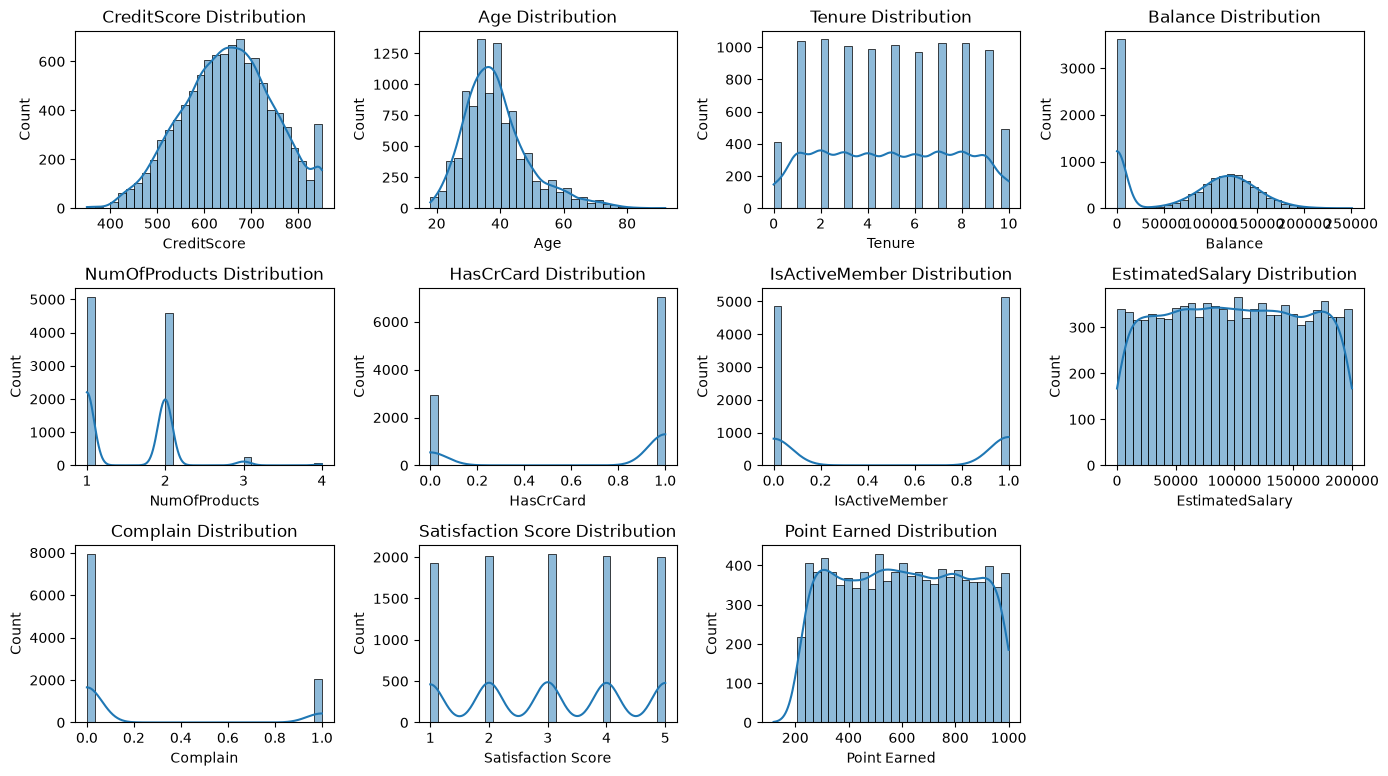

In [81]:
# Plot numerical distributions with KDE curves
fig, axes = plt.subplots(4, 4, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.histplot(data=df, x=col, kde=True, bins=30, ax=axes[i])
    axes[i].set_title(f'{col} Distribution')

# Remove unused axes
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

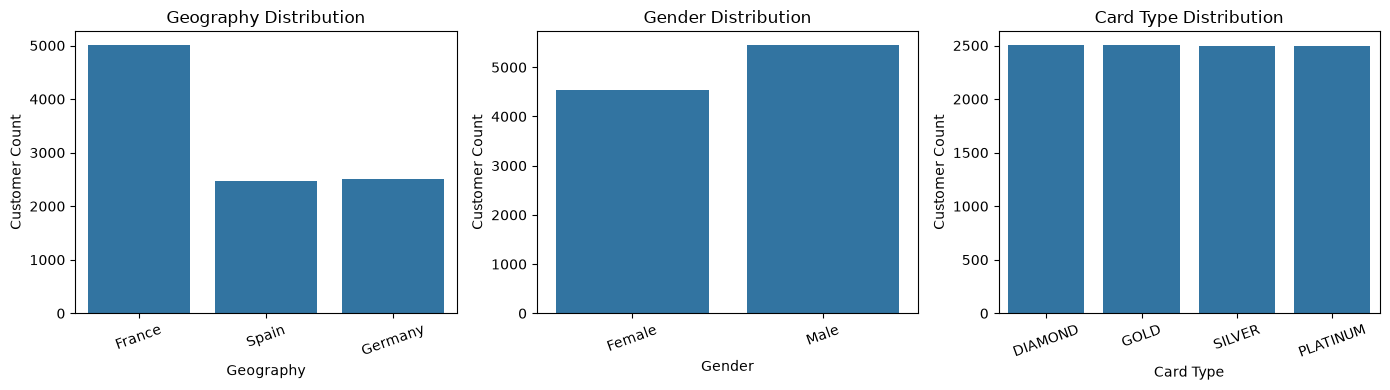

In [82]:
categorical_cols = ['Geography', 'Gender', 'Card Type']

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for col, ax in zip(categorical_cols, axes):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(f'{col} Distribution')
    ax.set_xlabel(col)
    ax.set_ylabel('Customer Count')
    ax.tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

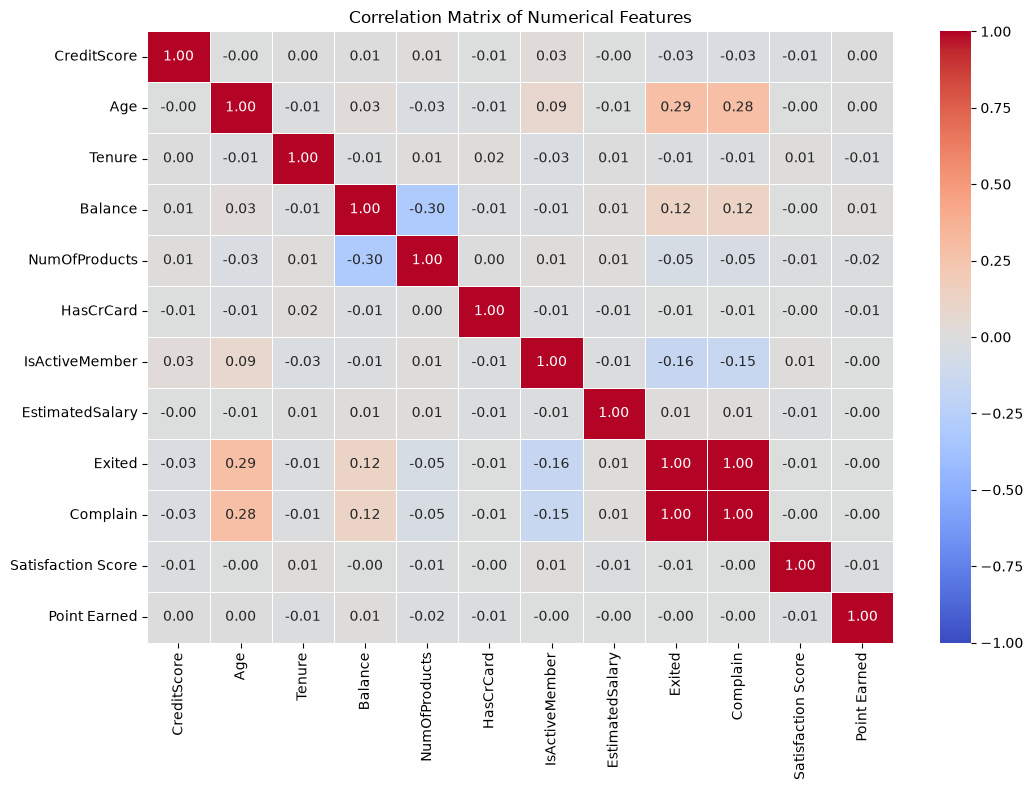

In [83]:
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title('Correlation Matrix of Numerical Features')
plt.tight_layout()
plt.show()

### Interpretation of the Correlation Matrix

The correlation analysis reveals that most numerical features have weak linear relationships with the target variable, `Exited`.

Among the ordinary numerical predictors, `Age` has the strongest positive correlation with customer churn (0.29), suggesting that older customers may be more likely to leave the bank. `Balance` also shows a weak positive correlation (0.12), while `IsActiveMember` has a weak negative correlation (-0.16), indicating that active customers may be less likely to churn.

Other features, including `CreditScore`, `Tenure`, `NumOfProducts`, `HasCrCard`, `EstimatedSalary`, and `Point Earned`, show very weak correlations with customer churn.

The matrix also reveals a negative correlation between `Balance` and `NumOfProducts` (-0.30), although this does not indicate a severe multicollinearity concern.

**An important observation** is the unusually high correlation between `Exited`, `Complain`, and `Satisfaction Score`, with values approximately equal to 1.00. These relationships require further investigation because they may indicate potential data leakage or features that are closely associated with the churn outcome.

Overall, the correlation analysis suggests that most individual numerical predictors have relatively weak linear relationships with customer churn. However, the unusually strong relationships involving `Complain` and `Satisfaction Score` should be investigated before proceeding to model development.

In [84]:
pd.crosstab(
    df['Exited'],
    df['Complain'],
    margins=True
)

Complain,0,1,All
Exited,,,
0,7952,10,7962
1,4,2034,2038
All,7956,2044,10000


### Handling Potential Data Leakage

The correlation analysis revealed an unusually strong relationship between `Complain` and the target variable, `Exited`, with a correlation coefficient of approximately 0.996.

Further investigation using a crosstab showed that almost all customers who churned had recorded complaints, while almost all retained customers had no complaints.

This relationship raises concerns about potential data leakage, particularly if complaint information is recorded after or during the churn process.

Therefore, `Complain` is excluded from the predictors at this stage to reduce the risk of the model relying on information that may not be available when predicting future customer churn.

The `Satisfaction Score` feature is retained because it has virtually no linear correlation with the target variable.

In [85]:
# Remove the feature strongly associated with the target
df.drop(columns=['Complain'], inplace=True)

print(f"Updated dataset shape: {df.shape}")

Updated dataset shape: (10000, 14)


In [86]:
categorical_features = [
    'Geography',
    'Gender',
    'NumOfProducts',
    'IsActiveMember'
]

for feature in categorical_features:
    churn_analysis = (
        df.groupby(feature)['Exited']
        .agg(
            Customer_Count='count',
            Churned_Customers='sum',
            Churn_Rate='mean'
        )
        .reset_index()
    )

    churn_analysis['Churn_Rate (%)'] = (
        churn_analysis['Churn_Rate'] * 100
    ).round(2)

    churn_analysis.drop(columns='Churn_Rate', inplace=True)

    print(f'\nChurn Analysis by {feature}')
    display(churn_analysis)


Churn Analysis by Geography


,Geography,Customer_Count,Churned_Customers,Churn_Rate (%)
0,France,5014,811,16.17
1,Germany,2509,814,32.44
2,Spain,2477,413,16.67



Churn Analysis by Gender


,Gender,Customer_Count,Churned_Customers,Churn_Rate (%)
0,Female,4543,1139,25.07
1,Male,5457,899,16.47



Churn Analysis by NumOfProducts


,NumOfProducts,Customer_Count,Churned_Customers,Churn_Rate (%)
0,1,5084,1409,27.71
1,2,4590,349,7.60
2,3,266,220,82.71
3,4,60,60,100.00



Churn Analysis by IsActiveMember


,IsActiveMember,Customer_Count,Churned_Customers,Churn_Rate (%)
0,0,4849,1303,26.87
1,1,5151,735,14.27


### Observations from Categorical Feature Analysis

The analysis revealed several differences in customer churn rates across the selected categorical features:

- **Geography:** Germany recorded the highest churn rate at 32.44%, compared with France (16.17%) and Spain (16.60%). This suggests that geographical location may be an important predictor of customer churn.

- **Gender:** Female customers had a higher churn rate (25.07%) than male customers (16.47%), indicating a noticeable difference in churn patterns between the two groups.

- **Number of Products:** Customers with two products had the lowest churn rate (7.60%), while customers with three and four products recorded considerably higher rates. However, these latter groups contain relatively few customers, so their results should be interpreted cautiously.

- **Active Membership:** Inactive customers had a higher churn rate (26.87%) than active customers (14.27%). This suggests that customer engagement may be associated with retention.

Overall, Geography, Gender, Number of Products, and Active Membership show differences in churn rates and may provide useful information for predicting customer churn. These relationships represent associations rather than causal effects.

### EDA Summary

The exploratory data analysis provided the following insights into the bank customer churn dataset:

**1. Target Variable Distribution**
- 7,962 customers (79.62%) were retained.
- 2,038 customers (20.38%) churned.
- The dataset is moderately imbalanced, with more retained customers than churned customers.

**2. Numerical Feature Analysis**
- Age showed the strongest positive correlation with churn among the ordinary numerical predictors (approximately 0.29).
- Balance had a relatively weak positive correlation with churn.
- Active membership showed a negative relationship with churn.
- Most other numerical features had weak linear relationships with the target.

**3. Categorical Feature Analysis**
- Customers in Germany recorded a higher churn rate (32.44%) than customers in France and Spain.
- Female customers had a higher churn rate (25.07%) than male customers (16.47%).
- Customers with two products had the lowest churn rate (7.60%).
- Inactive customers had a higher churn rate (26.87%) than active customers (14.27%).

**4. Correlation Analysis**
- `Complain` had an extremely high correlation with `Exited` (approximately 0.996). This raises a potential target leakage concern that must be investigated before model training.
- `Satisfaction Score` had almost no linear correlation with the target.
- No other strong predictor-to-predictor correlations were identified that immediately require feature removal.

**5. Data Quality**
- No missing values were identified.
- No duplicate rows were identified.
- Identifier columns (`RowNumber`, `CustomerId`, and `Surname`) were excluded from the working dataset because they do not provide meaningful predictive information in this task.

**Conclusion**

The EDA identified several features associated with customer churn, including Age, Geography, Gender, Number of Products, and Active Membership.

The target variable is moderately imbalanced, which should be considered during model evaluation.

Before training, the potential leakage associated with `Complain` must be investigated. The next stage will focus on preparing the dataset, selecting appropriate features, encoding categorical variables, and splitting the data for model development.

# Data Preprocessing

The goal of this stage is to prepare the dataset for machine learning by selecting the relevant features, handling categorical variables, and preparing the data for model training.

### Feature Selection

First, we'll separate the independent variables (features) from the dependent variable (target).

In [87]:
# Separate features and target variable

X = df.drop(columns=['Exited'])
y = df['Exited']

print(f"Feature dataset shape: {X.shape}")
print(f"Target dataset shape: {y.shape}")

display(X.head())

Feature dataset shape: (10000, 13)
Target dataset shape: (10000,)


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Satisfaction Score,Card Type,Point Earned
0,619,France,Female,42,2,0.00,1,1,1,"101,348.88",2,DIAMOND,464
1,608,Spain,Female,41,1,"83,807.86",1,0,1,"112,542.58",3,DIAMOND,456
2,502,France,Female,42,8,"159,660.80",3,1,0,"113,931.57",3,DIAMOND,377
3,699,France,Female,39,1,0.00,2,0,0,"93,826.63",5,GOLD,350
4,850,Spain,Female,43,2,"125,510.82",1,1,1,"79,084.10",5,GOLD,425


### Feature and Target Selection

The dataset was divided into independent variables (`X`) and the dependent variable (`y`).

- `X` contains the 13 customer-related features used for prediction.
- `y` contains the `Exited` column, which represents the customer churn outcome.

The `Complain` feature was excluded due to its potential target leakage concern.

In [88]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (8000, 13)
Testing features: (2000, 13)
Training target: (8000,)
Testing target: (2000,)


### Train-Test Split

The dataset was divided into training and testing sets using an 80:20 ratio.

The training set will be used to develop the machine learning model, while the testing set will evaluate its performance on unseen data.

Stratified sampling was applied to preserve the original distribution of churned and retained customers across both sets. A random state of 42 was used to ensure reproducibility.

In [89]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify categorical and numerical features
categorical_cols = X.select_dtypes(include=['object']).columns
numerical_cols = X.select_dtypes(include=['number']).columns

# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_cols)
    ]
)

# Fit on training data and transform both datasets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training data:", X_train_processed.shape)
print("Processed testing data:", X_test_processed.shape)

Processed training data: (8000, 16)
Processed testing data: (2000, 16)
